# Redes Neurais Recorrentes com dados de voos da ANAC (VRA)

**Objetivo:** prever o **atraso médio das partidas de Guarulhos (SBGR) na próxima hora** a partir do que aconteceu nas últimas 24 horas, usando três tipos de rede recorrente: **SimpleRNN, LSTM e GRU**.

**Dados:** Voo Regular Ativo (VRA) da ANAC, janeiro e fevereiro de 2026 (`VRA_2026_01.csv` e `VRA_2026_02.csv`), disponíveis em [dados.gov.br](https://dados.gov.br/dados/conjuntos-dados/dadosabertos-areas-de-atuacao-voos-e-operacoes-aereas-voo-regular-ativo-vra).

**Roteiro**
1. Carregar e limpar a base
2. Transformar voos individuais em uma **série temporal horária**
3. Explorar a série
4. Criar **janelas deslizantes** (o formato que uma RNN espera)
5. Dividir treino / validação / teste **respeitando o tempo**
6. Construir **baselines** simples (toda rede precisa vencê-los para valer a pena)
7. Treinar SimpleRNN, LSTM e GRU
8. Comparar e interpretar

> **Como rodar no Google Colab:** `Ambiente de execução → Executar tudo`. Se os CSVs não estiverem na pasta do notebook, a célula de carregamento baixa os arquivos diretamente da ANAC. Outra opção é enviá-los pelo ícone de pasta à esquerda.

## Por que uma rede *recorrente*?

Uma rede densa comum recebe um vetor e não sabe que a posição 1 veio antes da posição 2. Uma **RNN** lê a sequência passo a passo e carrega um **estado oculto** $h_t$ que resume o que viu até ali:

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$

Na prática, a SimpleRNN tem dificuldade para lembrar coisas de muitos passos atrás (o gradiente "some" ao voltar no tempo). Por isso surgiram:

- **LSTM:** adiciona uma *célula de memória* e três portas (esquecer, entrada, saída) que decidem o que guardar e o que descartar.
- **GRU:** versão simplificada, com duas portas. Costuma ter desempenho parecido com menos parâmetros.

Aqui cada passo da sequência é **uma hora**, e $x_t$ traz informações daquela hora em Guarulhos (quantos voos, atraso médio, cancelamentos, hora do dia...).

In [ ]:
# ---------------------------------------------------------------------------
# Bibliotecas
# (no Colab todas já vêm instaladas; em outro ambiente, descomente a linha abaixo)
# !pip install tensorflow pandas scikit-learn matplotlib
# ---------------------------------------------------------------------------
import os, random, urllib.request
import numpy as np                      # operações com vetores/matrizes
import pandas as pd                     # leitura e manipulação de tabelas
import matplotlib.pyplot as plt         # gráficos
import tensorflow as tf                 # framework de deep learning
from tensorflow import keras            # API de alto nível para montar as redes
from tensorflow.keras import layers     # camadas (SimpleRNN, LSTM, GRU, Dense...)
from sklearn.preprocessing import StandardScaler   # padronização (média 0, desvio 1)

# Semente fixa: torna os resultados reproduzíveis (mesma inicialização dos pesos,
# mesma ordem aleatória). Em GPU ainda pode haver pequenas variações.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4)   # tamanho padrão dos gráficos
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Carregar e limpar a base

In [ ]:
# ---------------------------------------------------------------------------
# Localização dos arquivos
# O script original usava a pasta do próprio arquivo .py (__file__), que não
# existe no Colab. Aqui procuramos os CSVs em pastas comuns e, se não
# encontrarmos, baixamos direto do servidor da ANAC.
# ---------------------------------------------------------------------------
NOMES = ["VRA_2026_01.csv", "VRA_2026_02.csv"]
PASTAS = [".", "dataset/raw", "/content", "/content/deep-learning-redes-recorrentes/dataset/raw"]
URL_ANAC = "https://siros.anac.gov.br/siros/registros/diversos/vra/2026/{}"


def localizar(nome):
    """Retorna o caminho do CSV; baixa da ANAC se ele não existir localmente."""
    for pasta in PASTAS:
        caminho = os.path.join(pasta, nome)
        if os.path.exists(caminho):
            return caminho
    print(f"Baixando {nome} da ANAC...")
    urllib.request.urlretrieve(URL_ANAC.format(nome), nome)
    return nome


ARQUIVOS = [localizar(n) for n in NOMES]
AEROPORTO = "SBGR"   # troque por SBSP, SBGL, SBBR, SBKP... para testar outro aeroporto

# Verifica se há GPU disponível (no Colab: Ambiente de execução → Alterar tipo → GPU)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"[Hardware] GPU disponível para TensorFlow: {gpus}")
else:
    print("[Hardware] TensorFlow em execução na CPU.")

# Lê os dois meses e empilha em um único DataFrame (uma linha = um voo).
# O VRA usa ';' como separador de colunas.
df = pd.concat([pd.read_csv(f, sep=";", encoding="utf-8") for f in ARQUIVOS], ignore_index=True)
print("Dados carregados com sucesso. Shape:", df.shape)

# Os nomes das colunas têm acentos ("Situação Voo", "Sigla ICAO Aeroporto Origem").
# Para não depender da codificação exata, localizamos as colunas por trechos do nome
# e as renomeamos para nomes simples.
col_situacao = [c for c in df.columns if "Situa" in c and "Voo" in c][0]
col_origem = [c for c in df.columns if "Origem" in c and "ICAO" in c][0]
df.rename(columns={col_situacao: "situacao_voo", col_origem: "origem"}, inplace=True)
display(df.head(3))

# Converte as colunas de horário (texto "dd/mm/aaaa hh:mm") para datetime.
# errors="coerce" transforma valores vazios/inválidos em NaT (data ausente).
fmt = "%d/%m/%Y %H:%M"
for col in ["Partida Prevista", "Partida Real", "Chegada Prevista", "Chegada Real"]:
    df[col] = pd.to_datetime(df[col], format=fmt, errors="coerce")

print("\nSituação dos voos:")
print(df["situacao_voo"].value_counts())

[Hardware] GPU disponível para TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dados carregados com sucesso. Shape: (171107, 21)


,Sigla ICAO Empresa Aérea,Empresa Aérea,Número Voo,Código DI,Código Tipo Linha,Modelo Equipamento,Número de Assentos,origem,Descrição Aeroporto Origem,Partida Prevista,...,Sigla ICAO Aeroporto Destino,Descrição Aeroporto Destino,Chegada Prevista,Chegada Real,situacao_voo,Justificativa,Referência,Situação Partida,Situação Chegada,Codeshare
0,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,3301,6,I,E145,50,SKBO,EL DORADO INTERNATIONAL AIRPORT - BOGOTÁ - COL...,14/01/2026 11:30,...,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,14/01/2026 14:30,14/01/2026 14:20,REALIZADO,NaN,14/01/2026 00:00:00,Pontual,Antecipado,NaN
1,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,3302,9,I,E145,50,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,14/01/2026 16:00,...,SYCJ,CHEDDI JAGAN INTERNATIONAL AIRPORT - GEORGETOW...,14/01/2026 17:55,14/01/2026 18:01,REALIZADO,NaN,14/01/2026 00:00:00,Pontual,Pontual,NaN
2,1ED,SERVICIOS AÉREOS PANAMERICANOS LTDA. SARPA S.A.S,3303,9,I,E145,50,SYCJ,CHEDDI JAGAN INTERNATIONAL AIRPORT - GEORGETOW...,14/01/2026 18:55,...,SBEG,EDUARDO GOMES - MANAUS - AM - BRASIL,14/01/2026 20:50,14/01/2026 21:43,REALIZADO,NaN,14/01/2026 00:00:00,Atraso 60-120,Atraso 30-60,NaN



Situação dos voos:
situacao_voo
REALIZADO    165914
CANCELADO      5193
Name: count, dtype: int64


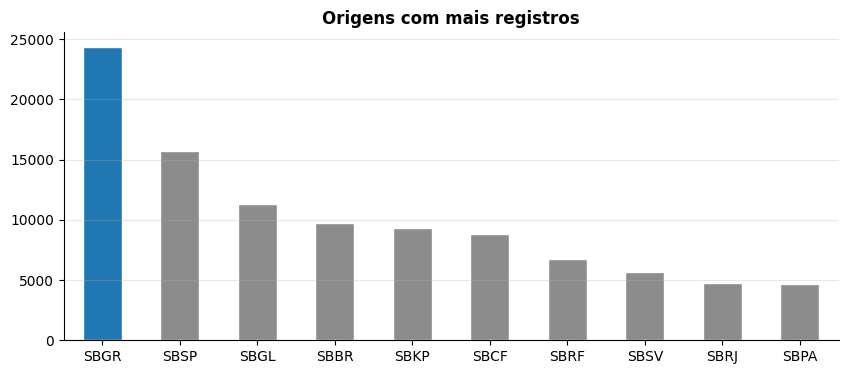

In [ ]:
import matplotlib.pyplot as plt

# Conta os registros por origem e pega os 10 maiores
top_origens = df['origem'].value_counts().head(10)

# Define as cores: azul para SBGR, cinza para os demais
cores = ['#1f77b4' if origem == 'SBGR' else '#8c8c8c' for origem in top_origens.index]

# Cria o gráfico de barras
plt.figure(figsize=(10, 4))
top_origens.plot(kind='bar', color=cores, edgecolor='white')
plt.title('Origens com mais registros', fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='-', alpha=0.3)

# Remove as bordas superior e direita para ficar mais parecido com a imagem
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.show()

Ficamos só com as **partidas** do aeroporto escolhido. O atraso de partida é `Partida Real − Partida Prevista`, em minutos.

Dois cuidados:
- Voos **cancelados** não têm horário real. Eles entram como *contagem de cancelamentos*, não como atraso.
- Há valores extremos (atrasos de dias, ou registros com partida muito antes do previsto). O atraso é limitado a **[-60, 300] min** para que poucos casos estranhos não dominem a média da hora.

In [ ]:
# Filtra apenas os voos que PARTEM do aeroporto escolhido
p = df[df["origem"] == AEROPORTO].copy()

# Sem horário previsto não dá para posicionar o voo no tempo -> descarta
p = p.dropna(subset=["Partida Prevista"])

# Atraso de partida em minutos (negativo = saiu antes do previsto).
# Para cancelados o resultado é NaN, pois não há partida real.
p["atraso_min"] = (p["Partida Real"] - p["Partida Prevista"]).dt.total_seconds() / 60

# Limita (clip) valores extremos: abaixo de -60 vira -60, acima de 300 vira 300
p["atraso_min"] = p["atraso_min"].clip(-60, 300)

# Indicador 0/1 de cancelamento
p["cancelado"] = (p["situacao_voo"] == "CANCELADO").astype(int)

display(p.head())

print(f"{len(p):,} partidas previstas em {AEROPORTO}  |  canceladas: {p['cancelado'].sum():,}")
print("\nEstatísticas descritivas do atraso (min):")
print(p["atraso_min"].describe().round(1))

,Sigla ICAO Empresa Aérea,Empresa Aérea,Número Voo,Código DI,Código Tipo Linha,Modelo Equipamento,Número de Assentos,origem,Descrição Aeroporto Origem,Partida Prevista,...,Chegada Prevista,Chegada Real,situacao_voo,Justificativa,Referência,Situação Partida,Situação Chegada,Codeshare,atraso_min,cancelado
9,AAL,"AMERICAN AIRLINES, INC.",0906,0,I,B772,288,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2026-01-01 00:15:00,...,2026-01-01 08:40:00,2026-01-01 08:28:00,REALIZADO,NaN,01/01/2026 00:00:00,Antecipado,Antecipado,NaN,-11.0,0
12,AAL,"AMERICAN AIRLINES, INC.",0930,0,I,B77W,318,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2026-01-01 23:30:00,...,2026-01-02 08:00:00,2026-01-02 08:43:00,REALIZADO,NaN,01/01/2026 00:00:00,Pontual,Atraso 30-60,NaN,25.0,0
15,AAL,"AMERICAN AIRLINES, INC.",0950,0,I,B789,295,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2026-01-01 23:00:00,...,2026-01-02 08:40:00,2026-01-02 08:41:00,REALIZADO,NaN,01/01/2026 00:00:00,Pontual,Pontual,NaN,3.0,0
17,AAL,"AMERICAN AIRLINES, INC.",0958,0,I,B772,288,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2026-01-01 22:35:00,...,2026-01-02 07:05:00,2026-01-02 07:12:00,REALIZADO,NaN,01/01/2026 00:00:00,Pontual,Pontual,NaN,6.0,0
18,AAL,"AMERICAN AIRLINES, INC.",0962,0,I,B789,295,SBGR,GUARULHOS - GOVERNADOR ANDRÉ FRANCO MONTORO - ...,2026-01-01 22:35:00,...,2026-01-02 08:55:00,2026-01-02 08:48:00,REALIZADO,NaN,01/01/2026 00:00:00,Pontual,Antecipado,NaN,2.0,0


23,875 partidas previstas em SBGR  |  canceladas: 556

Estatísticas descritivas do atraso (min):
count    23319.0
mean        14.0
std         33.4
min        -60.0
25%         -2.0
50%          4.0
75%         18.0
max        300.0
Name: atraso_min, dtype: float64


## 2. De voos para série temporal horária

Cada linha do VRA é um voo. A RNN precisa de uma **sequência regular no tempo**, então os dados são agregados por hora (pelo horário *previsto* de partida):

| feature | significado |
|---|---|
| `n_voos` | partidas previstas na hora |
| `atraso_medio` | atraso médio dos voos realizados (**é o que queremos prever**) |
| `pct_atrasados` | fração com mais de 15 min de atraso |
| `n_cancel` | voos cancelados |
| `hora_sin`, `hora_cos` | hora do dia em forma circular (23h fica perto de 0h) |
| `fim_semana` | sábado ou domingo |

Horas sem nenhum voo realizado ficam com atraso 0 e são sinalizadas por `n_voos`.

In [ ]:
# "Arredonda" o horário previsto para baixo, até a hora cheia (ex.: 14:37 -> 14:00).
# Essa será a chave de agrupamento.
p["hora"] = p["Partida Prevista"].dt.floor("h")

# Para estatísticas de atraso usamos só voos realizados (cancelados não têm atraso)
realizados = p[p["cancelado"] == 0]

# Cada coluna é uma agregação por hora; o pandas alinha tudo pelo índice "hora"
serie = pd.DataFrame({
    "n_voos": p.groupby("hora").size(),                                   # total de partidas previstas
    "atraso_medio": realizados.groupby("hora")["atraso_min"].mean(),       # ALVO
    "pct_atrasados": realizados.groupby("hora")["atraso_min"].apply(lambda s: (s > 15).mean()),
    "n_cancel": p.groupby("hora")["cancelado"].sum(),
})

# Grade horária completa (jan/01 00h a fev/28 23h): horas sem nenhum voo não
# aparecem no groupby, então reindexamos e preenchemos as lacunas com 0.
inicio, fim = pd.Timestamp("2026-01-01 00:00"), pd.Timestamp("2026-02-28 23:00")
serie = serie.reindex(pd.date_range(inicio, fim, freq="h")).fillna(0)

# Codificação cíclica da hora: seno e cosseno colocam 23h e 0h lado a lado,
# o que não aconteceria usando a hora como número de 0 a 23.
h = serie.index.hour
serie["hora_sin"] = np.sin(2 * np.pi * h / 24)
serie["hora_cos"] = np.cos(2 * np.pi * h / 24)

# 1 para sábado/domingo (dayofweek 5 e 6), 0 para dias úteis
serie["fim_semana"] = (serie.index.dayofweek >= 5).astype(int)

print(serie.shape)   # (horas, colunas)
serie.head(24)

(1416, 7)


,n_voos,atraso_medio,pct_atrasados,n_cancel,hora_sin,hora_cos,fim_semana
2026-01-01 00:00:00,5.0,47.000000,0.200000,0.0,0.000000e+00,1.000000e+00,0
2026-01-01 01:00:00,4.0,-3.750000,0.000000,0.0,2.588190e-01,9.659258e-01,0
2026-01-01 02:00:00,1.0,-4.000000,0.000000,0.0,5.000000e-01,8.660254e-01,0
2026-01-01 03:00:00,5.0,-1.500000,0.000000,3.0,7.071068e-01,7.071068e-01,0
2026-01-01 04:00:00,0.0,0.000000,0.000000,0.0,8.660254e-01,5.000000e-01,0
2026-01-01 05:00:00,3.0,5.333333,0.333333,0.0,9.659258e-01,2.588190e-01,0
2026-01-01 06:00:00,3.0,-3.666667,0.000000,0.0,1.000000e+00,6.123234e-17,0
2026-01-01 07:00:00,28.0,5.964286,0.142857,0.0,9.659258e-01,-2.588190e-01,0
2026-01-01 08:00:00,27.0,15.703704,0.259259,0.0,8.660254e-01,-5.000000e-01,0
2026-01-01 09:00:00,20.0,-5.200000,0.000000,0.0,7.071068e-01,-7.071068e-01,0


## 3. Explorando a série

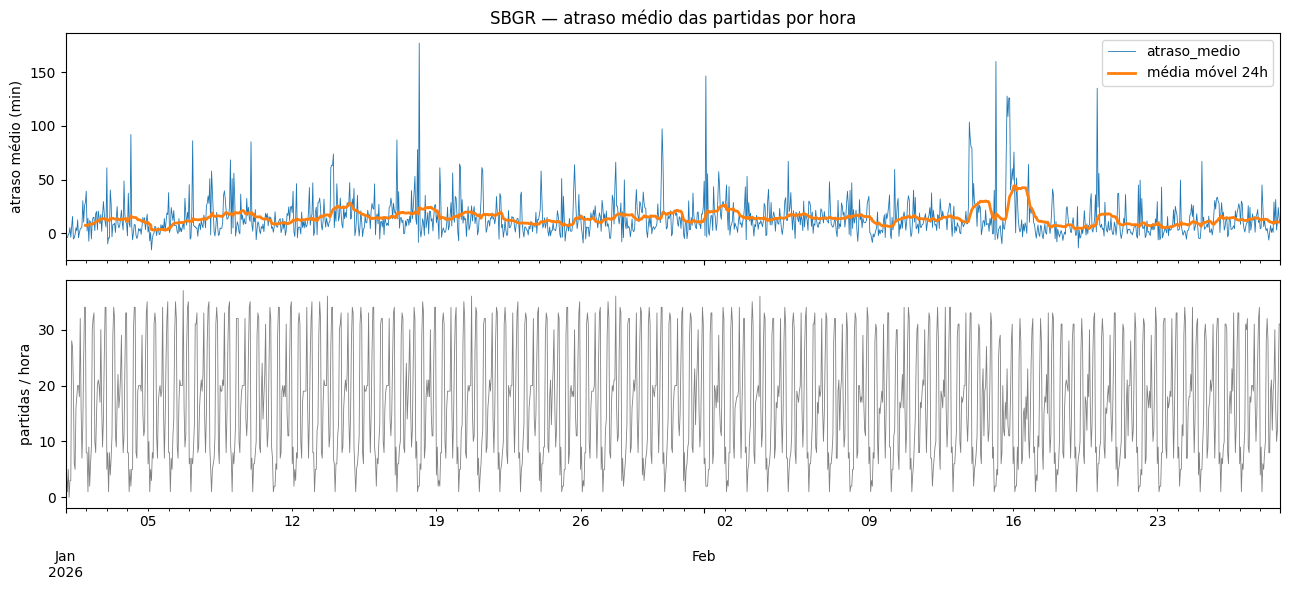

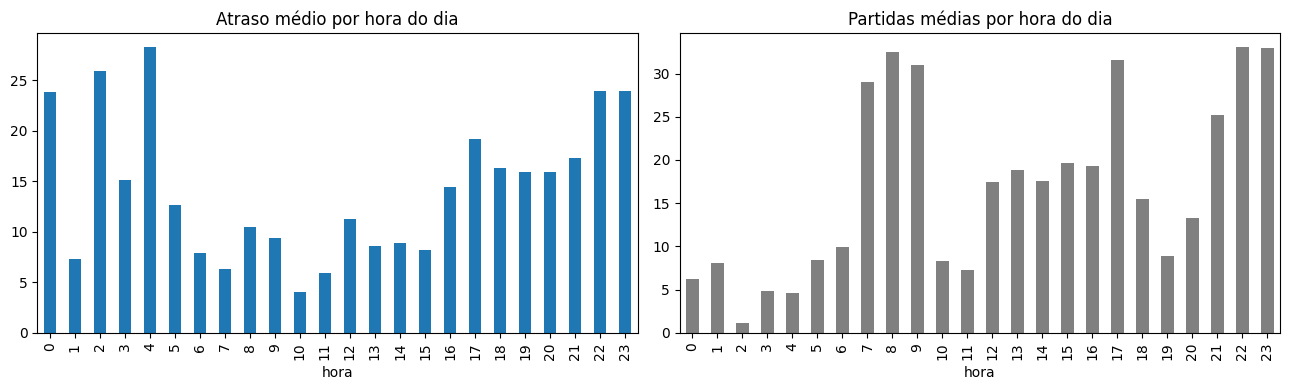

In [ ]:
# Pasta onde os gráficos também serão salvos em PNG (além de exibidos na tela)
os.makedirs("figuras", exist_ok=True)

# Gráfico 1: atraso médio hora a hora (linha fina) + média móvel de 24 h (linha grossa),
# e abaixo o número de partidas por hora.
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
serie["atraso_medio"].plot(ax=ax[0], lw=0.6)
serie["atraso_medio"].rolling(24).mean().plot(ax=ax[0], lw=2, label="média móvel 24h")
ax[0].set_ylabel("atraso médio (min)"); ax[0].legend()
serie["n_voos"].plot(ax=ax[1], lw=0.6, color="gray")
ax[1].set_ylabel("partidas / hora")
ax[0].set_title(f"{AEROPORTO} — atraso médio das partidas por hora")
plt.tight_layout()
plt.savefig("figuras/01_serie_temporal.png", dpi=150)
plt.show()

# Gráfico 2: perfil médio por hora do dia (ciclo diário)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
serie.groupby(serie.index.hour)["atraso_medio"].mean().plot.bar(ax=ax[0], color="tab:blue")
ax[0].set_title("Atraso médio por hora do dia"); ax[0].set_xlabel("hora")
serie.groupby(serie.index.hour)["n_voos"].mean().plot.bar(ax=ax[1], color="gray")
ax[1].set_title("Partidas médias por hora do dia"); ax[1].set_xlabel("hora")
plt.tight_layout()
plt.savefig("figuras/02_atraso_por_hora.png", dpi=150)
plt.show()

Repare em dois padrões que a RNN pode aprender: o **ciclo diário** (o atraso cresce ao longo do dia, quando atrasos anteriores se propagam) e a **persistência** (uma hora ruim costuma ser seguida de outra ruim). A madrugada tem poucos voos, então a média ali é mais ruidosa.

## 4. Janelas deslizantes

Uma RNN no Keras recebe um tensor 3D: **(amostras, passos no tempo, features)**.

Com `JANELA = 24`, cada amostra é: *as 24 horas anteriores (todas as features)* → *o atraso médio da hora seguinte*.

```
horas  t-24 ... t-2  t-1  |  t
       [------- X -------]  -> y
```

## 5. Divisão temporal (treino / validação / teste)

Em série temporal **nunca** se embaralha antes de dividir, porque isso deixaria o modelo "ver o futuro". A divisão usada é:

- **treino:** 01/jan a 05/fev
- **validação:** 06/fev a 16/fev (para escolher quando parar o treino)
- **teste:** 17/fev a 28/fev (só olhamos no final)

O `StandardScaler` é ajustado **só no treino** e depois aplicado aos outros conjuntos.

In [ ]:
FEATURES = ["atraso_medio", "n_voos", "pct_atrasados", "n_cancel", "hora_sin", "hora_cos", "fim_semana"]
ALVO = "atraso_medio"   # variável que a rede vai prever
JANELA = 24             # quantas horas passadas a rede enxerga

# Últimas horas de treino e de validação (o restante é teste)
fim_treino, fim_val = pd.Timestamp("2026-02-05 23:00"), pd.Timestamp("2026-02-16 23:00")

# Padronização: média e desvio calculados SÓ com o período de treino (.loc[:fim_treino])
# e depois aplicados à série inteira. Assim nenhuma estatística do futuro vaza para o treino.
scaler_x = StandardScaler().fit(serie.loc[:fim_treino, FEATURES])   # para as entradas
scaler_y = StandardScaler().fit(serie.loc[:fim_treino, [ALVO]])     # para o alvo (permite desfazer depois)
X_all = scaler_x.transform(serie[FEATURES])
y_all = scaler_y.transform(serie[[ALVO]]).ravel()


def criar_janelas(X, y, janela):
    """Monta as amostras da RNN: X = horas [t-janela, t-1], y = valor na hora t."""
    Xs, ys, idx = [], [], []
    for t in range(janela, len(X)):
        Xs.append(X[t - janela:t])   # horas t-janela ... t-1 (todas as features)
        ys.append(y[t])              # hora t (a "próxima")
        idx.append(serie.index[t])   # guarda a data/hora do alvo para dividir por período
    return np.array(Xs), np.array(ys), pd.DatetimeIndex(idx)


X, y, tempo = criar_janelas(X_all, y_all, JANELA)

# Máscaras booleanas pela data do ALVO: cada amostra vai para treino, validação ou teste
tr, va, te = tempo <= fim_treino, (tempo > fim_treino) & (tempo <= fim_val), tempo > fim_val
X_tr, y_tr, X_va, y_va, X_te, y_te = X[tr], y[tr], X[va], y[va], X[te], y[te]

print("formato de X:", X.shape, "-> (amostras, horas, features)")
print(f"treino {len(X_tr)} | validação {len(X_va)} | teste {len(X_te)}")

X_tr.shape, X_va.shape,X_te.shape

formato de X: (1392, 24, 7) -> (amostras, horas, features)
treino 840 | validação 264 | teste 288


((840, 24, 7), (264, 24, 7), (288, 24, 7))

## 6. Baselines

Antes de qualquer rede, três regras simples. Se a RNN não vencer essas, ela não está aprendendo nada útil.

- **Persistência:** a próxima hora terá o mesmo atraso da hora atual.
- **Mesma hora de ontem:** o atraso de 24 h atrás.
- **Média por hora do dia:** o atraso médio daquela hora no período de treino.

A métrica é o **MAE** (erro absoluto médio), em minutos: "em média, erramos o atraso médio da próxima hora por X minutos".

In [ ]:
real = serie[ALVO]                    # alvo em minutos (sem padronização)
idx_te = tempo[te]                    # datas/horas das amostras de teste
y_real_te = real.loc[idx_te].values   # valores reais do teste, em minutos


def mae(a, b):
    """Erro absoluto médio entre dois vetores."""
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

# Média do alvo para cada hora do dia, calculada apenas no treino
media_por_hora = real.loc[:fim_treino].groupby(real.loc[:fim_treino].index.hour).mean()

baselines = {
    "Persistência (hora anterior)": real.shift(1).loc[idx_te].values,    # shift(1): valor de 1 h antes
    "Mesma hora de ontem": real.shift(24).loc[idx_te].values,           # shift(24): valor de 24 h antes
    "Média por hora do dia": media_por_hora.loc[idx_te.hour].values,    # perfil horário do treino
}

# Dicionário que acumulará o MAE de teste de todos os modelos (baselines + redes)
resultados = {nome: mae(y_real_te, prev) for nome, prev in baselines.items()}
print("Resultados dos Baselines (MAE teste em minutos):")
print(pd.Series(resultados, name="MAE teste (min)").round(2))

Resultados dos Baselines (MAE teste em minutos):
Persistência (hora anterior)    11.05
Mesma hora de ontem             12.34
Média por hora do dia           10.92
Name: MAE teste (min), dtype: float64


## 7. Treinando as redes recorrentes

As três redes têm a mesma estrutura. Só muda a camada recorrente:

```
Entrada (24 horas × 7 features)
   → camada recorrente (32 unidades)
   → Dropout 20%
   → Dense(1)  = atraso médio previsto para a próxima hora
```

O `EarlyStopping` interrompe o treino quando o erro na validação para de melhorar e volta aos melhores pesos. A perda é **Huber**, menos sensível a horas com atraso extremo do que o erro quadrático.

In [ ]:
# 1e-3 = 0.001
opt = keras.optimizers.Adam(learning_rate=0.001)

def construir(tipo, unidades=32):
    """Cria e compila uma rede recorrente do tipo pedido (SimpleRNN, LSTM ou GRU)."""
    camada = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[tipo]
    modelo = keras.Sequential([
        layers.Input(shape=(JANELA, len(FEATURES))),   # cada amostra: 24 passos x 7 features
        camada(unidades),                              # lê a sequência e devolve o estado final (32 valores)
        layers.Dropout(0.2),                           # zera 20% dos valores no treino (reduz overfitting)
        layers.Dense(1),                               # saída linear: 1 número (atraso padronizado)
    ], name=tipo)
    # Adam com taxa de aprendizado 0,001; perda Huber; MAE acompanhado como métrica
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mean_squared_error", metrics=["mae"])
    #modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss=keras.losses.Huber(), metrics=["mae"])
    #modelo.compile(optimizer=opt, loss="mean_squared_error", metrics=["mae"])
    return modelo

modelo = construir("LSTM")
modelo.summary()   # mostra camadas e número de parâmetros
#modelo.info_model()                        # mostra parâmetros treináveis

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_27 (LSTM)                  │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_50 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,153 (20.13 KB)

 Trainable params: 5,153 (20.13 KB)

 Non-trainable params: 0 (0.00 B)

Arquitetura do modelo


Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_14 (SimpleRNN)       │ (None, 32)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_51 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,941 (15.40 KB)

 Trainable params: 1,313 (5.13 KB)

...

 Total params: 11,909 (46.52 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,940 (31.02 KB)

GRU        épocas:  48   MAE teste: 9.27 min
Diagrama


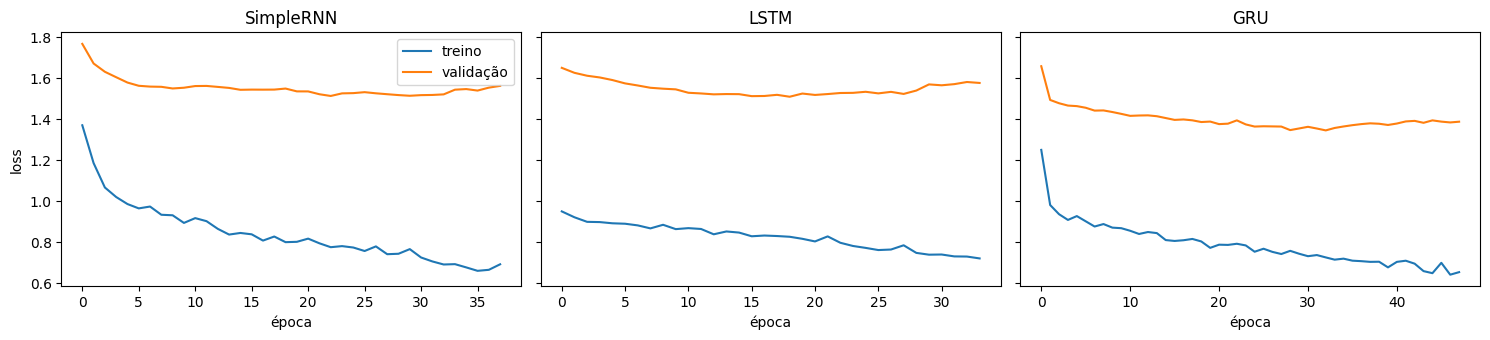

In [ ]:
historicos, previsoes = {}, {}
for tipo in ["SimpleRNN", "LSTM", "GRU"]:
    tf.random.set_seed(SEED)          # mesma semente para as três redes -> comparação justa
    modelo = construir(tipo)

    # Para o treino se a perda de validação não melhorar por 15 épocas seguidas
    # e restaura os pesos da melhor época
    parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

    hist = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                      epochs=200, batch_size=32, callbacks=[parar], verbose=0)

    print("Arquitetura do modelo")
    modelo.summary()

    # A rede prevê na escala padronizada; inverse_transform volta para minutos
    prev = scaler_y.inverse_transform(modelo.predict(X_te, verbose=0)).ravel()

    historicos[tipo], previsoes[tipo] = hist.history, prev
    resultados[tipo] = mae(y_real_te, prev)
    print(f"{tipo:9s}  épocas: {len(hist.history['loss']):3d}   MAE teste: {resultados[tipo]:.2f} min")

print("Diagrama")
# Curvas de aprendizado: perda de treino x validação por época, para cada rede
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (tipo, h) in zip(axs, historicos.items()):
    ax.plot(h["loss"], label="treino"); ax.plot(h["val_loss"], label="validação")
    ax.set_title(tipo); ax.set_xlabel("época")
axs[0].set_ylabel("loss"); axs[0].legend()
plt.tight_layout()
plt.savefig("figuras/03_curvas_aprendizado.png", dpi=150)
plt.show()

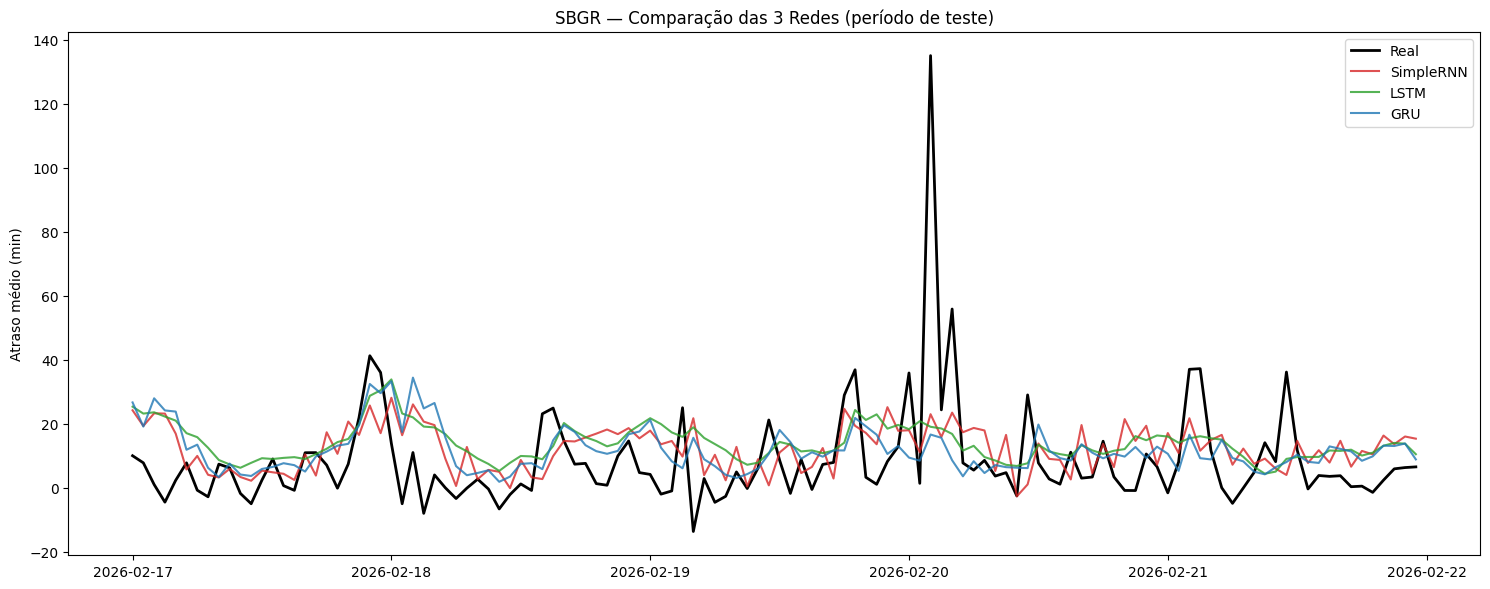

In [ ]:
import matplotlib.pyplot as plt

# Seleciona um trecho para o gráfico (ex: os primeiros 5 dias do teste)
janela_plot = slice(0, 24 * 5)

plt.figure(figsize=(15, 6))
# Plota o valor real em destaque
plt.plot(idx_te[janela_plot], y_real_te[janela_plot], label="Real", color="black", lw=2)

# Plota a previsão das 3 redes
cores = {"SimpleRNN": "tab:red", "LSTM": "tab:green", "GRU": "tab:blue"}
for tipo in ["SimpleRNN", "LSTM", "GRU"]:
    plt.plot(idx_te[janela_plot], previsoes[tipo][janela_plot], label=tipo, color=cores[tipo], lw=1.5, alpha=0.8)

plt.ylabel("Atraso médio (min)")
plt.title(f"{AEROPORTO} — Comparação das 3 Redes (período de teste)")
plt.legend()
plt.tight_layout()
plt.show()

As curvas mostram se houve *overfitting*: quando a perda de treino continua caindo e a de validação sobe, o modelo começou a decorar o treino. O `EarlyStopping` guarda os pesos do ponto de menor perda na validação.

## 8. Comparação final

,MAE teste (min),vs. melhor baseline
GRU,9.27,-1.65
SimpleRNN,9.88,-1.04
LSTM,10.21,-0.71
Média por hora do dia,10.92,0.00
Persistência (hora anterior),11.05,0.13
Mesma hora de ontem,12.34,1.42


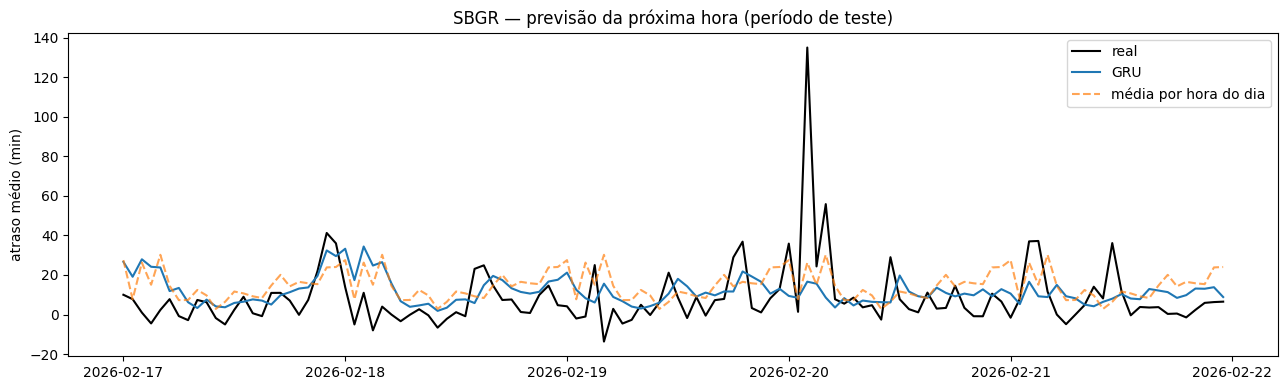

In [ ]:
# Tabela ordenada pelo MAE de teste; a 2ª coluna mostra a diferença para o melhor baseline
# (negativo = a rede é melhor que o melhor baseline)
tabela = pd.Series(resultados, name="MAE teste (min)").sort_values().round(2).to_frame()
tabela["vs. melhor baseline"] = (tabela.iloc[:, 0] - min(resultados[b] for b in baselines)).round(2)
display(tabela)

# Melhor das três redes (menor MAE de teste)
melhor = min(["SimpleRNN", "LSTM", "GRU"], key=resultados.get)
janela_plot = slice(0, 24 * 5)   # primeiros 5 dias do teste

# Real x previsto pela melhor rede x baseline "média por hora do dia"
plt.figure(figsize=(13, 4))
plt.plot(idx_te[janela_plot], y_real_te[janela_plot], label="real", color="black", lw=1.5)
plt.plot(idx_te[janela_plot], previsoes[melhor][janela_plot], label=melhor, lw=1.5)
plt.plot(idx_te[janela_plot], baselines["Média por hora do dia"][janela_plot],
         label="média por hora do dia", ls="--", alpha=0.7)
plt.ylabel("atraso médio (min)"); plt.title(f"{AEROPORTO} — previsão da próxima hora (período de teste)")
plt.legend(); plt.tight_layout()
plt.savefig("figuras/04_previsao_comparativa.png", dpi=150)
plt.show()

## Como ler o resultado

- Se as redes ficaram **abaixo** dos baselines, elas aprenderam algo além do ciclo diário, tipicamente a propagação de atrasos de uma hora para a seguinte combinada com o horário.
- Se ficaram **próximas** ou **acima**, isso é comum com apenas ~1.400 horas de dados: o sinal é ruidoso (o atraso médio de uma hora com 3 voos varia muito) e um baseline bem escolhido já captura boa parte do padrão. É um resultado honesto e importante de mostrar em uma apresentação.
- LSTM e GRU geralmente superam a SimpleRNN quando a janela é longa, porque lembram melhor o início da sequência.

## Exercícios para ir além

1. **Mais dados:** baixe outros meses do VRA e acrescente em `NOMES`. Redes recorrentes melhoram muito com mais histórico.
2. **Janela maior:** teste `JANELA = 48` ou `168` (uma semana) e compare SimpleRNN × LSTM.
3. **Outros aeroportos:** mude `AEROPORTO` para `"SBSP"` (Congonhas) ou `"SBBR"` (Brasília).
4. **Novas features:** atraso médio das *chegadas* em SBGR, ou o atraso dos voos que partiram de outros aeroportos com destino a SBGR (o atraso "chega voando").
5. **Previsão de vários passos:** troque `Dense(1)` por `Dense(6)` para prever as próximas 6 horas de uma vez.
6. **Classificação:** em vez do atraso médio, prever se mais de 30% dos voos da próxima hora vão atrasar (`sigmoid` + `binary_crossentropy`).
7. **Clima:** junte dados meteorológicos (METAR/ASOS) de SBGR. Chuva e vento costumam explicar boa parte dos atrasos.